<a href="https://colab.research.google.com/github/ravidatt/AirTravelReservation/blob/master/build_a_neural_network_in_pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Build Neural Network in PyTorch

In [15]:
import torch
import torch.nn as nn # neural network
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

np.random.seed(42)
torch.manual_seed(42)

print("PyTorch version:", torch.__version__)


PyTorch version: 2.11.0+cu130


## make_moon - 2 features, 2 classes

X.shape = (500, 2), y.shape = (500,)
X_temp.shape = (400, 2) y_temp.shape = (400,)
X_test.shape = (100, 2) y_test.shape = (100,)
X_train.shape = (350, 2) y_train.shape = (350,)
X_val.shape = (50, 2) y_val.shape = (50,)


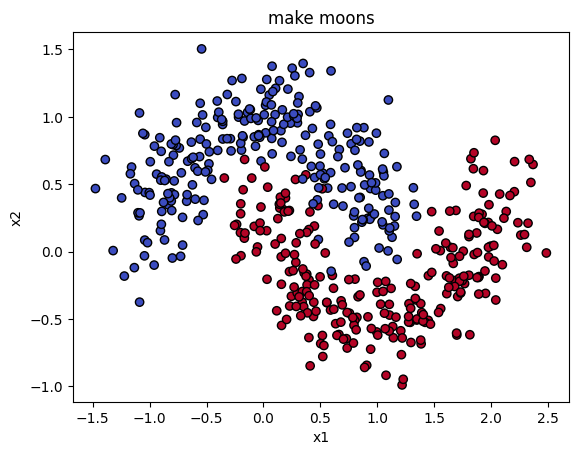

In [16]:
X, y = make_moons(n_samples=500, noise=0.2, random_state=42)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2
                                                    , random_state=42)


X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.125
                                                    , random_state=42)

print(f"X.shape = {X.shape}, y.shape = {y.shape}")


print(f"X_temp.shape = {X_temp.shape} y_temp.shape = {y_temp.shape}")
print(f"X_test.shape = {X_test.shape} y_test.shape = {y_test.shape}")

print(f"X_train.shape = {X_train.shape} y_train.shape = {y_train.shape}")

print(f"X_val.shape = {X_val.shape} y_val.shape = {y_val.shape}")


plt.scatter(X[:,0], X[:,1], c=y.ravel(), cmap='coolwarm', edgecolor='k')
plt.title('make moons');
plt.xlabel("x1");
plt.ylabel("x2");
plt.show()



In [17]:
import pandas as pd

# Create a DataFrame to inspect correlations
df = pd.DataFrame(X, columns=['x1', 'x2'])
correlation = df.corr()
display(correlation)

# Calculate class-wise correlation
for class_label in [0, 1]:
    class_corr = df[y == class_label].corr().iloc[0, 1]
    print(f"Correlation between x1 and x2 for Class {class_label}: {class_corr:.4f}")

,x1,x2
x1,1.000000,-0.400767
x2,-0.400767,1.000000


Correlation between x1 and x2 for Class 0: -0.0200
Correlation between x1 and x2 for Class 1: 0.0603


### Relationship Analysis between $x_1$ and $x_2$:

1. **Geometrical/Spatial Relationship**:
   * Geometrically, the features construct a non-linear relationship that forms two interlocking semi-circles (crescents).
   * As $x_1$ increases or decreases, $x_2$ moves up and down following a curved pathway (a sinusoidal or quadratic-like arc).

2. **Linear Correlation**:
   * If you look at the correlation coefficient across the **entire dataset**, there is typically a weak, slightly negative correlation.
   * However, when looking at each class individually, they show specific curves. For example, for Class 0 (the top moon), $x_2$ increases and then decreases as $x_1$ goes from left to right.

In [18]:
print(X[:5])
print(y[:5])

[[ 0.83085779 -0.33434228]
 [ 0.99170955  0.87899966]
 [ 1.1072453  -0.47034376]
 [-0.14089918  1.03314844]
 [ 0.40559217  1.32852876]]
[1 0 1 0 0]


## Numpy --> tensors

In [19]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"device =  {device}")

device =  cuda


In [20]:
def t_T(a):
  return torch.tensor(a, dtype=torch.float32, device=device)

X_train, y_train = t_T(X_train), t_T(y_train)
X_val, y_val = t_T(X_val), t_T(y_val)
X_test, y_test = t_T(X_test), t_T(y_test)

print(f"X_train.shape = {X_train.shape} y_train.shape = {y_train.shape}")
print(f"X_val.shape = {X_val.shape} y_val.shape = {y_val.shape}")
print(f"X_test.shape = {X_test.shape} y_test.shape = {y_test.shape}")


X_train.shape = torch.Size([350, 2]) y_train.shape = torch.Size([350])
X_val.shape = torch.Size([50, 2]) y_val.shape = torch.Size([50])
X_test.shape = torch.Size([100, 2]) y_test.shape = torch.Size([100])


## Define the model

##### Shape : 2 (input) -> 4 (neuron, sigmoid) -> 4 (neuron activation) -> 1, all sigmoid. (nn. Sequential is a shorter way; we use nn.Module since you will need it for bigger model )

In [24]:
class Net(nn.Module):
  def __init__(self):
    super().__init__()
    self.fc1 = nn.Linear(2,4) # fc : fully connected layer; fc1; input layer
    self.fc2 = nn.Linear(4,4) # hidden layer 1
    self.fc3 = nn.Linear(4,1) # hidden layer 2

  def forward(self, x):
    x = torch.sigmoid(self.fc1(x))
    x = torch.sigmoid(self.fc2(x))
    x = torch.sigmoid(self.fc3(x))
    return x




In [25]:
model = Net().to(device)
print(model)


Net(
  (fc1): Linear(in_features=2, out_features=4, bias=True)
  (fc2): Linear(in_features=4, out_features=4, bias=True)
  (fc3): Linear(in_features=4, out_features=1, bias=True)
)


# Loss & optimizer  

##### BCELoss + SGD -- mirrors Section 3. (Modern default: ReLU hidden + BCEWithLogitsLOss; more on that later.)